# Model pipeline: work in progress

Ongoing notebook: from the raw data to a first validated model, before cross-validation.

**Pipeline**

| Step | What | Status |
|---|---|---|
| 0 | Load the data (cached `.npy`), labels to {0, 1} | ok |
| 1 | Take a 50k-row random subsample | ok |
| 2 | Split the subsample 80% training / 20% validation | ok |
| 3 | Preprocess: **fit + transform + bias on the training part**, then **transform + bias on the validation part** | ok |
| 4 | Train L2-regularized logistic regression on the training part |ok  |
| 5 | Predict on the validation part and analyse (probabilities → best threshold → F1) |  F1 ≈ 0.45, threshold ≈ 0.25 |
| next | Stratified k-fold cross-validation, then experiments |  |


### Setup

In [21]:
import sys
sys.path.insert(0, "..")   # also look in the parent folder (the repo root)

import numpy as np
import helpers
import preprocessing
import implementations
from itertools import combinations, product
import matplotlib.pyplot as plt

data_path = "../data/dataset"

## Functions

**Metric**
- **F1 score.** Each prediction is a true positive (TP), false positive (FP), false negative (FN) or true
  negative (TN). Precision = TP / (TP + FP), recall = TP / (TP + FN), and F1 is their harmonic mean.
  F1 ignores the true negatives, which suits our imbalanced data: predicting "healthy" for everyone gives
  TP = 0, so F1 = 0.
- **Best threshold.** The model outputs probabilities. With ~9% positives, the default cut at 0.5 predicts
  almost nobody as positive, so we try thresholds between 0 and 1 and keep the one with the best F1.

**Data**
- `subsample`: random distinct rows, x and y selected with the same indices so they stay aligned.
- `split_data`: shuffles the row indices and cuts them into a training part and a validation part.
- `prepare_features`: step 3 (fit on training, transform both, add bias) in a single call. Not used below,
  where step 3 is written out; it will be used in the cross-validation loop.

In [22]:
def f1_score(y_true, y_pred):
    """
    F1 score of binary predictions.

    Args:
        y_true (np.array): true labels in {0, 1}, shape (N,)
        y_pred (np.array): predicted labels in {0, 1}, shape (N,)

    Returns:
        f1 (float): F1 score, 0.0 if there is no true positive (also avoids dividing by zero)
    """
    TP = np.sum((y_true == 1) & (y_pred == 1))
    FP = np.sum((y_true == 0) & (y_pred == 1))
    FN = np.sum((y_true == 1) & (y_pred == 0))

    if TP == 0:
        return 0.0

    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1 = 2 * (precision*recall) / (precision+recall)

    return f1


def best_threshold(y_true, scores):
    """
    Find the threshold on the probability scores that gives the best F1.

    Args:
        y_true (np.array): true labels in {0, 1}, shape (N,)
        scores (np.array): predicted probabilities in [0, 1] (sigmoid of tx @ w), shape (N,)

    Returns:
        best_t (float): threshold with the best F1 (predict 1 if score >= best_t)
        best_f1 (float): F1 obtained with that threshold
    """
    thresholds = np.quantile(scores, np.linspace(0, 1, 101)) # different thresholds between 0 and 1 (steps of 0.01)

    f1_scores = []

    for t in thresholds:
        y_pred = (scores>=t).astype(int)
        f1 = f1_score(y_true, y_pred)

        f1_scores.append(f1)

    best_idx = np.argmax(f1_scores)

    best_t = thresholds[best_idx]
    best_f1 = f1_scores[best_idx]

    return best_t, best_f1


def subsample(x_train, y_train, size, rng):
    """
    Random subsample of the rows.

    Args:
        x_train (np.array): features, shape (N, D)
        y_train (np.array): labels, shape (N,)
        size (int): number of rows to keep
        rng (np.random.Generator): random generator, e.g. np.random.default_rng(42)

    Returns:
        x_sub (np.array): `size` distinct random rows of x_train, shape (size, D)
        y_sub (np.array): the matching labels, shape (size,)
    """
    idx = rng.choice(len(y_train), size=size, replace=False)  # `size` distinct row numbers in 0..N-1 - no replace avoid duplication

    return x_train[idx], y_train[idx]   # same idx for x and y: rows stay aligned


def split_data(x, y, ratio, rng):
    """
    Random split into a training part and a validation part.

    Args:
        x (np.array): features, shape (N, D)
        y (np.array): labels, shape (N,)
        ratio (float): share of the rows used for training (e.g. 0.8)
        rng (np.random.Generator): random generator

    Returns:
        x_tr, y_tr (np.array): training rows and labels (ratio * N rows)
        x_val, y_val (np.array): validation rows and labels (the rest)
    """
    cut = int(ratio*len(y))

    idx = rng.permutation(len(y))   # shuffled row numbers
    idx_tr = idx[:cut]
    idx_val = idx[cut:]

    x_tr, y_tr   = x[idx_tr], y[idx_tr]
    x_val, y_val = x[idx_val], y[idx_val]

    return x_tr, y_tr, x_val, y_val


def prepare_features(x_tr, x_val, names):
    """
    Fit the preprocessing on the training part only, transform both parts, add the bias.

    Args:
        x_tr (np.array): raw training features, shape (N_tr, 321)
        x_val (np.array): raw validation features, shape (N_val, 321)
        names (list): the 321 column names (preprocessing.load_feature_names)

    Returns:
        tx_tr (np.array): training matrix, standardized, bias column first
        tx_val (np.array): validation matrix, same columns, with the training statistics
    """
    params = preprocessing.fit_preprocessing(x_tr, names)
    tx_tr  = preprocessing.add_bias(preprocessing.transform(x_tr, params))
    tx_val = preprocessing.add_bias(preprocessing.transform(x_val, params))
    return tx_tr, tx_val


def feature_names(params):
    """Names of the columns of add_bias(transform(x, params)), in the same order."""
    out = ["bias"]
    for info in params["columns"]:
        if "categories" in info:
            out += [f"{info['name']}={c:g}" for c in info["categories"]]  # one 0/1 column per category
        else:
            out.append(info["name"])
            if info["add_flag"]:
                out.append(f"{info['name']}_missing")
    return out


def pick_top(tx_tr, w, top, max_corr=0.9):
    """
    The `top` largest-weight features, skipping near-duplicates of a feature already picked.

    Args:
        tx_tr (np.array): standardized training matrix, bias column first
        w (np.array): weights of a fit on tx_tr, shape (D,)
        top (int): number of features to pick
        max_corr (float): skip a feature whose |correlation| with a picked one is above this (1.0 = keep all)

    Returns:
        picked (np.array): column indices of the picked features, strongest first
    """
    n = len(tx_tr)
    picked = []
    for j in 1 + np.argsort(-np.abs(w[1:])):            # strongest first, bias excluded
        # the columns are standardized, so their correlation is the mean of their product
        if all(abs(tx_tr[:, j] @ tx_tr[:, k]) / n <= max_corr for k in picked):
            picked.append(j)
        if len(picked) == top:
            break
    return np.array(picked)


def add_interactions(tx_tr, tx_val, w, degree=2, top=30, max_corr=0.9, max_gb=3.0):
    """
    Products of 2..degree distinct features among the `top` strongest ones, standardized with training stats.

    Args:
        tx_tr, tx_val (np.array): standardized matrices, bias column first
        w (np.array): weights of a fit on tx_tr, used to rank the features
        degree (int): 1 = unchanged, 2 = + pairs, 3 = + pairs and triples
        top (int): number of strongest features combined (see pick_top)
        max_corr (float): near-duplicates above this |correlation| are skipped (e.g. MAXVO2_ vs FC60_)
        max_gb (float): refuse to build a training matrix bigger than this (8 GB of RAM)

    Returns:
        tx_tr, tx_val (np.array): new matrices with C(top, 2) [+ C(top, 3)] product columns appended
    """
    if degree < 2:
        return tx_tr, tx_val
    best = pick_top(tx_tr, w, top, max_corr)
    combos = [c for d in range(2, degree + 1) for c in combinations(best, d)]
    gb = 8 * len(tx_tr) * (tx_tr.shape[1] + len(combos)) / 1e9
    if gb > max_gb:
        raise MemoryError(f"{len(combos)} products -> {gb:.1f} GB training matrix: lower top or degree")
    p_tr = np.column_stack([np.prod(tx_tr[:, list(c)], axis=1) for c in combos])
    p_val = np.column_stack([np.prod(tx_val[:, list(c)], axis=1) for c in combos])
    mean, std = p_tr.mean(0), p_tr.std(0)
    std[std == 0] = 1
    return np.hstack([tx_tr, (p_tr - mean) / std]), np.hstack([tx_val, (p_val - mean) / std])


**Tests of the metric on hand-made arrays** (expected values computed by hand).

In [23]:
y_true_test = np.array([1, 0, 1, 0])
print(f1_score(y_true_test, np.array([1, 0, 1, 0])))   # 1.0    perfect
print(f1_score(y_true_test, np.array([0, 0, 0, 0])))   # 0.0    predicts nobody
print(f1_score(y_true_test, np.array([1, 1, 1, 1])))   # 0.667  TP=2, FP=2, FN=0
print(f1_score(y_true_test, np.array([1, 0, 0, 0])))   # 0.667  TP=1, FP=0, FN=1

print(best_threshold(np.array([0, 0, 1, 1]), np.array([0.1, 0.4, 0.35, 0.8])))   # (0.11, 0.8)

1.0
0.0
0.6666666666666666
0.6666666666666666
(np.float64(0.1075), np.float64(0.8))


## Step 0: load the data

`helpers.load_csv_data` reads the CSV files with `np.genfromtxt`, which takes about 1.5 minutes.
The first cell is run **once** to cache the arrays as `.npy` files in `data/` (ignored by git);
afterwards the second cell reloads them in under a second.

The labels come as {-1, 1}: logistic regression needs **{0, 1}** (1 = heart disease).

**Checks:** 328,135 training rows and 109,379 test rows with 321 features; about 8.8% positives
(heavily imbalanced classes).

In [24]:
## ONE TIME ONLY: read the CSV files and save the numpy arrays
## (done: the .npy cache is in ../data - uncomment only to rebuild it, takes ~5 min)

# x_train, x_test, y_train, train_ids, test_ids = helpers.load_csv_data(data_path)

# np.save("../data/x_train.npy", x_train)
# np.save("../data/x_test.npy", x_test)
# np.save("../data/y_train.npy", y_train)
# np.save("../data/train_ids.npy", train_ids)
# np.save("../data/test_ids.npy", test_ids)

In [25]:
# 0 - load the datas

x_train = np.load("../data/x_train.npy")
x_test = np.load("../data/x_test.npy")
y_train = np.load("../data/y_train.npy")
test_ids = np.load("../data/test_ids.npy")   # needed later for the submission file

y = (y_train == 1).astype(int)   # labels {-1, 1} -> {0, 1}

names = preprocessing.load_feature_names(data_path)   # the 321 column names, needed by the preprocessing

## dim check
print(x_train.shape, y.shape, x_test.shape, test_ids.shape)   # (328135, 321) (328135,) (109379, 321) (109379,)
print(np.mean(y))                                             # ~0.088

(328135, 321) (328135,) (109379, 321) (109379,)
0.08830207079403295


## Step 1: 50k-row subsample

**Why a subsample?** While developing, we run the pipeline many times (bugs, parameters). On 50k rows a
run takes seconds instead of minutes, and the preprocessing needs much less memory (on all 328k rows the
matrix alone is ~1 GB). The validation part still has ~900 positives, enough for a reasonably stable F1.
The best settings will be confirmed on the full data, and the final model is always trained on all rows.

**Seed:** one random generator with a fixed seed, so the subsample and the split are the same at every
run (reproducible).

In [26]:
rng = np.random.default_rng(42)

# 1 - from the loaded data - take a 50k rows subsample
x_sub, y_sub = subsample(x_train, y, 50_000, rng)
print(x_sub.shape, y_sub.shape, y_sub.mean())   # (50000, 321) (50000,) ~0.088

(50000, 321) (50000,) 0.0894


## Step 2: split 80% training / 20% validation

The split is done on the **raw** data, before any preprocessing: the validation part must stay
completely unseen until we evaluate.

In [27]:
# 2 - from the subsample split the data - 80% training / 20% validation (preprocess after and test the model on it)
x_tr, y_tr, x_val, y_val = split_data(x_sub, y_sub, 0.8, rng)
print(x_tr.shape, x_val.shape, y_tr.mean(), y_val.mean())   # (40000, 321) (10000, 321) ~0.088 ~0.088

(40000, 321) (10000, 321) 0.08935 0.0896


## Step 3: preprocessing

### 3a. Training part: fit + transform + bias

1. `fit_preprocessing` learns every cleaning statistic on the **training part only**: answer codes, kept
   columns, categories, medians, clip bounds, mean/std.
2. `transform` applies them: a standardized matrix without NaN.
3. `add_bias` adds a column of 1s on the left. It comes **after** standardization: standardizing a
   constant column would turn it into 0s.

**Checks:** no NaN; every feature has mean ≈ 0 and std ≈ 1; the bias column is all 1s. On a 50k
subsample there can be slightly fewer columns than on the full data (349): rare categories missing from
the subsample get no one-hot column.

In [28]:
# 3 - preprocess the training data - fit + transform + biais
params = preprocessing.fit_preprocessing(x_tr, names)          # statistics learned on the training part only
tx_tr = preprocessing.add_bias(preprocessing.transform(x_tr, params))

## checks
col_mean = tx_tr[:, 1:].mean(axis=0)   # column by column, without the bias column
col_std  = tx_tr[:, 1:].std(axis=0)
print(tx_tr.shape)
print(np.abs(col_mean).max())          # should be ~0 (e.g. 1e-14)
print(col_std.min(), col_std.max())    # should both be ~1
print(np.all(tx_tr[:, 0] == 1))        # bias column is all 1s -> True
print(np.isnan(tx_tr).sum())           # should be 0

(40000, 347)
3.7006586250248885e-13
0.9999999999991572 1.0000000000008558
True
0


### 3b. Validation part: transform + bias (no fit)

The validation part is transformed with the **training statistics** (`params`). Fitting on it would leak
information from the rows we evaluate on and make the score optimistic.

**Checks:** same number of columns as the training matrix, no NaN. Means and stds are close to 0 and 1
but not exactly, since they were computed on the training part.

In [29]:
# 3 - preprocess the validation data with the fit of train data - transform + biais
tx_val = preprocessing.add_bias(preprocessing.transform(x_val, params))

## checks
print(tx_val.shape, tx_val.shape[1] == tx_tr.shape[1])   # same columns -> True
print(np.isnan(tx_val).sum())                            # should be 0

(10000, 347) True
0


## Step 4: train L2-regularized logistic regression

| Parameter | Value | Why |
|---|---|---|
| `lambda_` | 1e-4 | Almost no regularization for a first run, to tune later. **1e-4, not 1e4**: 1e4 makes the training diverge. |
| `initial_w` | zeros | One weight per column; zero = probability 0.5 for everyone. |
| `max_iters` | 500 | To check: does the loss still change with 1000? |
| `gamma` | 0.1 | Step size; if the loss becomes `nan`, lower it. |

The returned loss is the mean logistic loss, without the penalty term.

In [30]:
# 4a - first fit, only to rank the features by |weight| (no interactions yet)
lambda_ = 1e-4
max_iters = 1000
gamma = 0.1 # step size

w0, loss0 = implementations.reg_logistic_regression(y_tr, tx_tr, lambda_, np.zeros(tx_tr.shape[1]), max_iters, gamma)
print("loss without interactions:", loss0)

loss without interactions: 0.22104752973442537


### 4a-bis. Which features matter?

The features are standardized, so the size of a weight is comparable across features: the change in log-odds for +1 std.

- **Left:** weight size by rank, to choose `TOP` below. There is no sharp elbow after the first two (`SEX`, `GENHLTH`): the 30 strongest hold only about a third of the total.
- **Right:** the 30 strongest, signed. Read the sign with the coding: yes/no questions are 1 = yes, 2 = no, so a blue bar on `CVDSTRK3` means a stroke *raises* the risk; `SEX` is 1 = male.
- Near-duplicates share or cancel their weight: age appears 4 times (`_AGE80`, `_AGEG5YR`, and `MAXVO2_`/`FC60_`, which are formulas of age and sex), `_RFCHOL` is `TOLDHI2` with the codes swapped (+0.13 / −0.13), `_RFHYPE5` = `BPHIGH4=1`.

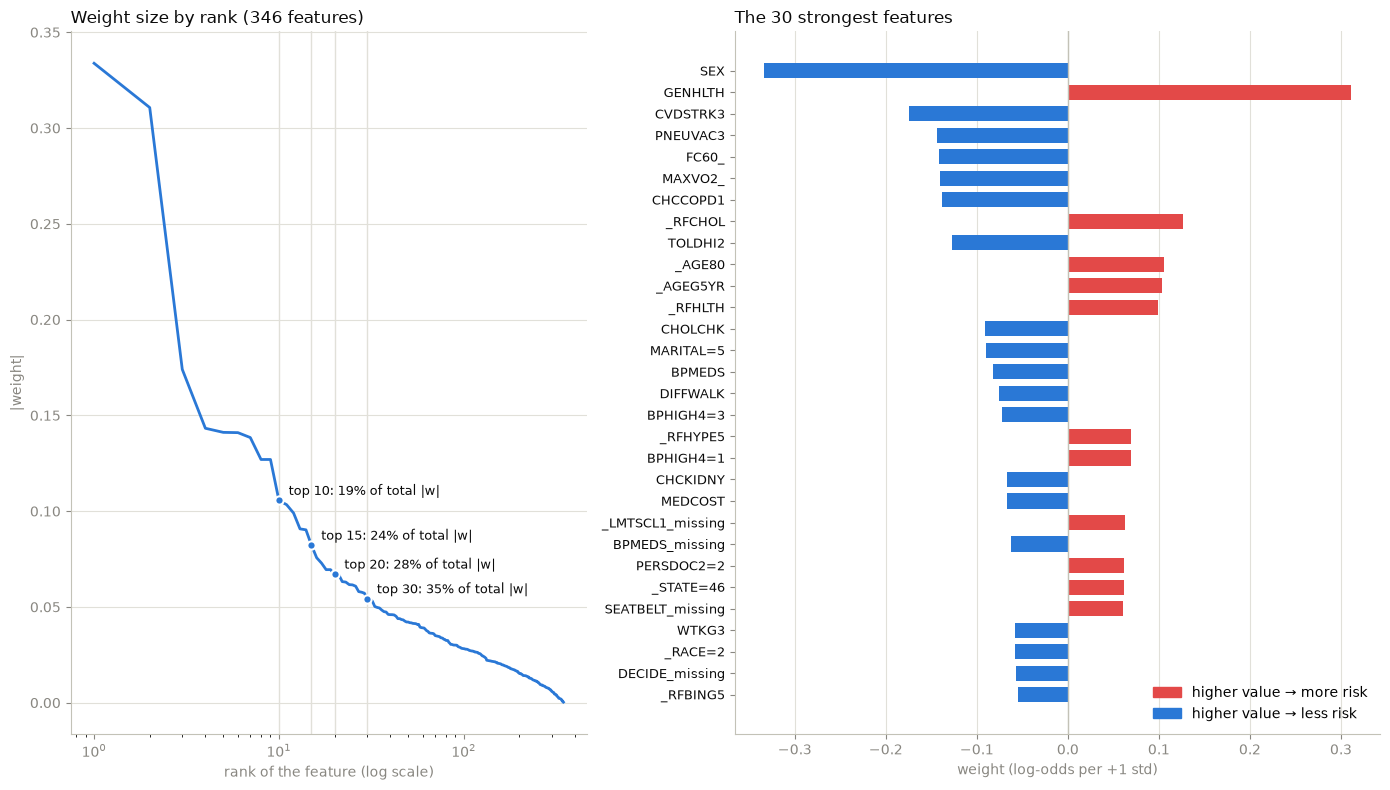

top 10: 19% of the total |w|, smallest kept |w| = 0.106
top 15: 24% of the total |w|, smallest kept |w| = 0.082
top 20: 28% of the total |w|, smallest kept |w| = 0.067
top 30: 35% of the total |w|, smallest kept |w| = 0.054


In [31]:
# 4a-bis - which features matter? Plot the weights of the first fit (w0) before choosing `top`
feat_names = feature_names(params)
assert len(feat_names) == len(w0)

# Features are standardized, so |w| is comparable: change in log-odds for +1 std of the feature
order = 1 + np.argsort(-np.abs(w0[1:]))          # strongest first, bias excluded
abs_sorted = np.abs(w0[order])
share = np.cumsum(abs_sorted) / abs_sorted.sum()  # share of the total |w| held by the top k

BLUE, RED, INK, MUTED, GRID, AXIS = "#2a78d6", "#e34948", "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7"
N_SHOW = 30
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.25]})

# Left: |w| by rank -> where the curve flattens is a natural `top` for add_interactions
ranks = np.arange(1, len(order) + 1)
ax1.plot(ranks, abs_sorted, color=BLUE, lw=2)
for k in (10, 15, 20, 30):
    ax1.axvline(k, color=GRID, lw=1, zorder=0)
    ax1.plot(k, abs_sorted[k - 1], "o", color=BLUE, ms=6, mec="white", mew=1.5)
    ax1.annotate(f"top {k}: {share[k - 1]:.0%} of total |w|", (k, abs_sorted[k - 1]),
                 xytext=(7, 4), textcoords="offset points", color=INK, fontsize=9)
ax1.set_xscale("log")
ax1.set_xlabel("rank of the feature (log scale)", color=MUTED)
ax1.set_ylabel("|weight|", color=MUTED)
ax1.set_title(f"Weight size by rank ({len(order)} features)", loc="left", color=INK)

# Right: the N_SHOW strongest features, signed. Red: a HIGHER value of the column raises the risk.
# Careful with yes/no questions: BRFSS codes 1 = yes, 2 = no, so blue on CVDSTRK3 means "yes (stroke) raises the risk"
top_idx = order[:N_SHOW][::-1]                   # strongest at the top of the chart
ax2.barh(np.arange(N_SHOW), w0[top_idx], height=0.7,
         color=[RED if w0[j] > 0 else BLUE for j in top_idx])
ax2.set_yticks(np.arange(N_SHOW), [feat_names[j] for j in top_idx], fontsize=9, color=INK)
ax2.axvline(0, color=AXIS, lw=1)
ax2.set_xlabel("weight (log-odds per +1 std)", color=MUTED)
ax2.set_title(f"The {N_SHOW} strongest features", loc="left", color=INK)
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RED), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
           labels=["higher value → more risk", "higher value → less risk"], loc="lower right", frameon=False)

for ax in (ax1, ax2):
    ax.grid(axis="x" if ax is ax2 else "y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(AXIS)
    ax.tick_params(colors=MUTED)
ax2.tick_params(axis="y", labelcolor=INK)  # feature names in ink, not muted
plt.tight_layout()
plt.show()

for k in (10, 15, 20, 30):
    print(f"top {k:2}: {share[k - 1]:.0%} of the total |w|, smallest kept |w| = {abs_sorted[k - 1]:.3f}")


### 4b. Interactions

`add_interactions(tx_tr, tx_val, w0, degree, top, max_corr)` adds the products of 2..`degree` features among the `top` strongest, **skipping near-duplicates** (|correlation| > `max_corr` with a stronger one), so pairs like `MAXVO2_ × FC60_` (≈ age²) are not built.

| degree, top | product columns added |
|---|---|
| 2, 30 | 435 |
| 3, 10 | 45 + 120 = 165 |
| 3, 15 | 105 + 455 = 560 |
| 3, 30 | 435 + 4,060 = 4,495 (refused: too big for 8 GB on the full data) |

On the 50k subsample the products overfit (log #17–#21); judge them on the full data (#32–#35). The new matrices get new names (`tx_tr_int`, `tx_val_int`), so this cell can be re-run with other settings.

In [32]:
# 4b - add the products of the strongest features, near-duplicates skipped
DEGREE = 2        # 1 = no interactions, 2 = + pairs, 3 = + pairs and triples
TOP = 30          # how many of the strongest features are combined (see the plot above)
MAX_CORR = 0.9    # skip a feature whose |correlation| with a stronger picked one is above this

picked = pick_top(tx_tr, w0, TOP, MAX_CORR)
ranked = 1 + np.argsort(-np.abs(w0[1:]))
cut = np.flatnonzero(ranked == picked[-1])[0]           # rank of the weakest picked feature
print(f"{len(picked)} features combined; skipped as near-duplicates:",
      [feat_names[j] for j in ranked[:cut] if j not in picked])

tx_tr_int, tx_val_int = add_interactions(tx_tr, tx_val, w0, DEGREE, TOP, MAX_CORR)
print(f"{tx_tr.shape[1]} → {tx_tr_int.shape[1]} columns")

# 4c - real fit on the widened matrices; λ 1e-3 keeps the products from overfitting (log #34 → #35)
lambda_ = 1e-3
initial_w = np.zeros(tx_tr_int.shape[1])
w, loss = implementations.reg_logistic_regression(y_tr, tx_tr_int, lambda_, initial_w, max_iters, gamma)
print("loss:", loss)

30 features combined; skipped as near-duplicates: ['MAXVO2_', 'TOLDHI2', '_AGE80', '_AGEG5YR', '_RFHYPE5', 'BPHIGH4=1', 'BPMEDS_missing']
347 → 782 columns
loss: 0.2160133419880868


## Step 5: prediction on the validation part + analysis

1. Scores `tx_val @ w` → probabilities with the sigmoid.
2. `best_threshold` picks the threshold with the best F1.

**First result:** loss ≈ 0.22; mean probability ≈ 0.10, close to the positive rate (well calibrated on
average); best threshold ≈ 0.25, well below 0.5 as expected with imbalanced classes; **F1 ≈ 0.45**.
One split only, so about ± 0.02 of noise: cross-validation will give a more reliable number.

In [33]:
# 5 - prediction on validation data (we ve just trained) + analyse
scores = helpers.sigmoid(tx_val_int @ w)   # sigmoid: probabilities in [0, 1]
print("scores min/mean/max:", scores.min(), scores.mean(), scores.max())
print("y_val:", np.unique(y_val, return_counts=True))

best_t, best_f1 = best_threshold(y_val, scores)
print("best threshold:", best_t, " validation F1:", best_f1)

scores min/mean/max: 0.0002258309003391412 0.09786962593784819 0.9587488519848504
y_val: (array([0, 1]), array([9104,  896]))
best threshold: 0.23827847186152043  validation F1: 0.45038167938931295


## Step 6: stratified k-fold cross-validation

- `build_k_indices`: k folds with ~9% positives each.
- `cross_validate`: for each fold, `prepare_features` → train → probabilities → `best_threshold`;
  return F1 mean ± std and the mean threshold.
- Check: each fold has ~8.8% positives, and the F1 std is small.

In [34]:
def build_k_indices(y, k_fold, rng):
    """
    Stratified k-fold split of the row indices. taking care about the positives repartition

    Args:
        y (np.array): labels in {0, 1}, shape (N,)
        k_fold (int): number of folds
        rng (np.random.Generator): random generator

    Returns:
        k_indices (list of np.array): k_fold arrays of row indices, ~N/k_fold rows each,
                                      with the same share of positives in each fold
    """
    # 1 - row numbers of each class
    idx_pos = np.where(y == 1)[0]
    idx_neg = np.where(y == 0)[0]

    # 2 - shuffle each class separately
    idx_pos = rng.permutation(idx_pos)
    idx_neg = rng.permutation(idx_neg)

    # 3 - cut each class into k_fold pieces (array_split keeps every row, even if N is not divisible)
    pos_parts = np.array_split(idx_pos, k_fold)
    neg_parts = np.array_split(idx_neg, k_fold)

    # 4 - fold i = piece i of the positives + piece i of the negatives
    k_indices = []
    for i in range(k_fold):
        folds = np.concatenate([pos_parts[i], neg_parts[i]])
        k_indices.append(folds)


    return k_indices


k_indices = build_k_indices(y_sub, 5, rng)

for i, fold in enumerate(k_indices):
    print(i, len(fold), y_sub[fold].mean())        # ~10 000 rows, ~0.089 each

all_idx = np.sort(np.concatenate(k_indices))
print(np.array_equal(all_idx, np.arange(len(y_sub))))   # True: every row exactly once



0 10000 0.0894
1 10000 0.0894
2 10000 0.0894
3 10000 0.0894
4 10000 0.0894
True


In [35]:
def cross_validate(x, y, names, k_indices, lambda_, gamma, max_iters, degree=2, top=30, max_corr=0.9):
    """
    k-fold cross-validation of L2-regularized logistic regression.

    Args:
        x (np.array): raw features, shape (N, 321)
        y (np.array): labels in {0, 1}, shape (N,)
        names (list): the 321 column names (preprocessing.load_feature_names)
        k_indices (list of np.array): folds from build_k_indices
        lambda_, gamma, max_iters: hyperparameters of reg_logistic_regression
        degree, top, max_corr: interactions added after the preprocessing (see add_interactions)

    Returns:
        f1_mean (float): mean validation F1 over the folds
        f1_std (float): standard deviation of the F1 over the folds
        t_mean (float): mean best threshold over the folds
    """
    f1s, thresholds = [], []

    for i in range(len(k_indices)):
        # 1 - validation = fold i, training = all the other folds + element definition
        idx_val = k_indices[i]
        idx_tr = np.concatenate([k_indices[j] for j in range(len(k_indices)) if j != i])

        x_tr, y_tr = x[idx_tr], y[idx_tr]
        x_val, y_val = x[idx_val], y[idx_val]

        # 2 - preprocessing: fit on the training folds only, transform both, add bias
        tx_tr, tx_val = prepare_features(x_tr, x_val, names)

        # 2b - interactions: rank with a first fit, add products of the `top` strongest features
        w0, _ = implementations.reg_logistic_regression(y_tr, tx_tr, lambda_, np.zeros(tx_tr.shape[1]), max_iters, gamma)
        tx_tr, tx_val = add_interactions(tx_tr, tx_val, w0, degree, top, max_corr)

        # 3 - train
        initial_w = np.zeros(tx_tr.shape[1])
        w, loss = implementations.reg_logistic_regression(y_tr, tx_tr, lambda_, initial_w, max_iters, gamma)

        # 4 - probabilities on the validation fold + best threshold
        scores = helpers.sigmoid(tx_val @ w)
        best_t, best_f1 = best_threshold(y_val, scores)

        f1s.append(best_f1)
        thresholds.append(best_t)
        print(f"fold {i}: loss {loss:.4f}, threshold {best_t:.2f}, F1 {best_f1:.3f}")

    return np.mean(f1s), np.std(f1s), np.mean(thresholds)



f1_mean, f1_std, t_mean = cross_validate(x_sub, y_sub, names, k_indices, 1e-4, 0.1, 500)
print(f"F1 = {f1_mean:.3f} ± {f1_std:.3f}, threshold = {t_mean:.2f}")

fold 0: loss 0.2166, threshold 0.24, F1 0.411
fold 1: loss 0.2176, threshold 0.20, F1 0.434
fold 2: loss 0.2180, threshold 0.19, F1 0.431


KeyboardInterrupt: 

In [ ]:
def grid_search(x, y, names, k_indices, lambdas, gammas, iters_list, degrees=(2,), tops=(30,)):
    """
    Grid search of the hyperparameters of reg_logistic_regression with k-fold cross-validation.
    First iterate over iters with fixed gamma, lambda - Second iterate over gamma with best iters and fixed lambda - Third iterate over lambda with best iters, gamma

    Args:
        x (np.array): raw features, shape (N, 321)
        y (np.array): labels in {0, 1}, shape (N,)
        names (list): the 321 column names
        k_indices (list of np.array): folds from build_k_indices (same folds for every configuration)
        lambdas (list): values of lambda_ to test
        gammas (list): values of gamma to test
        iters_list (list): values of max_iters to test
        degrees, tops (list): interaction settings to test (degree 1 = no interactions)

    Returns:
        results (list of tuples): (lambda_, gamma, max_iters, f1_mean, f1_std, t_mean, degree, top) for every combination
        best (tuple): the row of results with the highest f1_mean
    """
    results = []

    for lambda_, gamma, max_iters, degree, top in product(lambdas, gammas, iters_list, degrees, tops):
        # 1 - evaluate this combination
        f1_mean, f1_std, t_mean = cross_validate(x, y, names, k_indices, lambda_, gamma, max_iters, degree, top)

        # 2 - store it (f1_mean stays at index 3)
        results.append((lambda_, gamma, max_iters, f1_mean, f1_std, t_mean, degree, top))

        print(f"λ={lambda_:g}, γ={gamma:g}, iters={max_iters}, degree={degree}, top={top}: "
              f"F1 {f1_mean:.3f} ± {f1_std:.3f}, threshold {t_mean:.2f}")

    # 3 - best combination = highest mean F1
    f1_means = np.array(results)[:, 3] # f1_means = [row[3] for row in results]
    best = results[np.argmax(f1_means)]

    return results, best



k_indices = build_k_indices(y_sub, 5, rng)   # once, before the search

iters_list=[1000]
gammas=[0.1] #[0.05, 0.1, 0.5] [0.01, 0.05, 0.1, 0.5, 1.0]
lambdas=[1e-4] # [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1] [0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
"also possible to try expand degree of some not one hot features"
#degrees = [1, 2, 3]


degrees = [2]    # 1 = no interactions; 3 = + triples (then lower top: C(top, 3) columns)
tops = [30]      # on x_sub the products overfit: run this grid on the full data (x_train, y)
results, best = grid_search(x_sub, y_sub, names, k_indices, lambdas, gammas, iters_list, degrees, tops)
print("best:", best)

fold 0: loss 0.2130, threshold 0.19, F1 0.412


KeyboardInterrupt: 